# CSCI 3003 - Data Visualization

## Lab 4: Matplotlib Foundations and Univariate Visualization

**Name:** STEVE TATSIGUIA  
**Date:** 2026-09-15  
**Version:** Student notebook

> Add your name and date before submitting.

## Purpose and learning objectives

Matplotlib gives you direct control over the parts of a static visualization. This lab introduces that control through categorical counts and quantitative distributions. By the end, you should be able to:

- Profile a new dataset before plotting it.
- Explain the roles of a Matplotlib Figure and Axes.
- Create bar charts and histograms with the object-oriented Matplotlib approach.
- Choose a bar chart for categorical frequencies and a histogram for a quantitative distribution.
- Add a title, axis labels, readable tick labels, and restrained styling.
- Explain briefly how histogram bins affect the pattern you see.
- Save a finished figure as an image file.
- Pose and investigate one defensible univariate question.

## I. Import packages and locate the data

This lab uses the simplified Palmer Penguins dataset. It contains measurements for 344 penguins from three species observed on three islands in the Palmer Archipelago, Antarctica. The data were collected from 2007 through 2009 and are available under a CC0 license.

**Source:** Horst, Hill, and Gorman (2020), [palmerpenguins](https://allisonhorst.github.io/palmerpenguins/). The original observations were collected by Dr. Kristen Gorman and the Palmer Station Long Term Ecological Research Program.

The configured Jupyter working directory should be `01-labs/`, which already contains `penguins.csv`. `Path.cwd()` shows the directory where Python is currently looking for files.

In [36]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [37]:
Path.cwd()

WindowsPath('c:/Users/steve/OneDrive/Documents/CSCI-3003-Data-Visualization/01-labs')

Create a relative path and check it before reading the file. `Path("penguins.csv")` means that the file should be inside the working directory shown above.

In [38]:
penguin_file = Path("penguins.csv")
penguin_file.exists()

True

In [39]:
penguins = pd.read_csv(penguin_file)
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## II. Profile the new dataset

Begin with the inspection routine from Lab 1. No single command tells the whole story: use several outputs as evidence.

In [40]:
penguins.shape

(344, 8)

In [41]:
penguins.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')

In [42]:
penguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


**Question 0:** Profile the data using several of the commands we have previously learned.

**Question 1:** What does one row represent? Identify two qualitative variables and two quantitative variables that could support a univariate visualization.

**Answer:** Each row represents a penguin. two qualitative variables are `species` and `island`. Quantitative variables are `body_mass_g` and `bill_depth_mm`




**Question 2:** Which variables contain missing values? Why should you check this before constructing a plot?

**Answer:** `sex` contain missing values and it's important, because it will explain any gap in my graph





### Create one familiar first plot

Before learning new Matplotlib syntax, use the pandas plotting approach from earlier labs. `.value_counts()` produces one count per category, and `.plot.bar()` sends those counts to Matplotlib.

In [43]:
species_counts = penguins["species"].value_counts()
species_counts

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

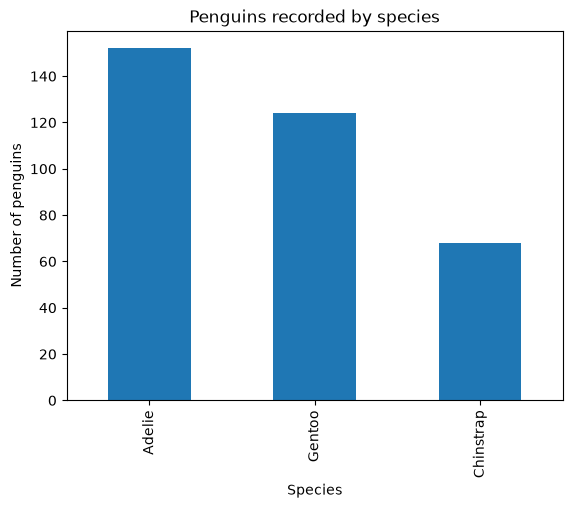

In [44]:
species_counts.plot.bar(
    title="Penguins recorded by species",
    xlabel="Species",
    ylabel="Number of penguins",
)
plt.show()

**Question 3:** What does one bar represent? Which species appears most often, and what does this graph *not* tell you about the wider penguin population?

**Answer:** One bar represent a species. Adelie appears the most. The graph does not tell you what island they come from





## III. Two paths to a Matplotlib graph

Pandas plotting methods are convenient because they start with a Series or DataFrame. Matplotlib can also create the plot directly.

The two cells below display the same graphs. Compare the syntax.

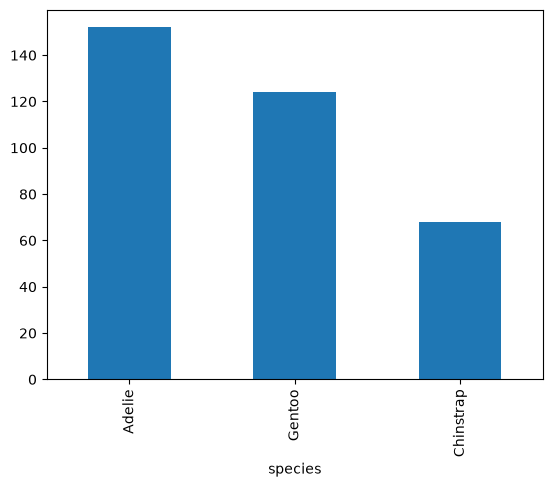

In [45]:
# Convenient pandas plotting method
species_counts.plot.bar()
plt.show()

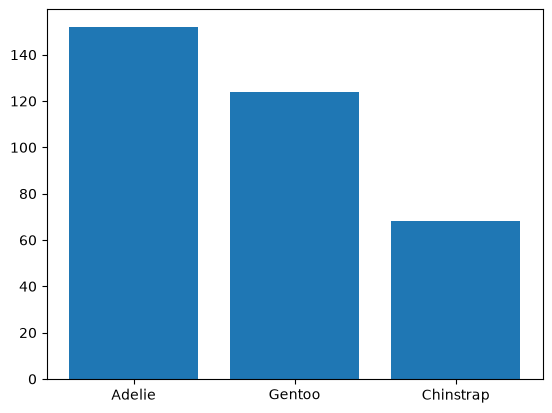

In [46]:
# Direct Matplotlib method
fig, ax = plt.subplots()
ax.bar(species_counts.index, species_counts.values)
plt.show()

In the direct version:

- `plt.subplots()` creates two related objects:
    - `fig`, a **Figure** -  refers to the complete figure—the full canvas that could contain one or more plots.
    -  `ax`, an **Axes** - refers to one the plotting area with its marks, scales, ticks, labels, and title.
- `ax.bar(x, height)` adds bars to that Axes.
- `plt.show()` displays the completed figure and is especially useful when a notebook contains several plots.

This course will usually use the explicit `fig, ax` approach when we want dependable control over a graph.

**Question 4:** In your own words, distinguish the Figure from the Axes. What does pandas save you from typing in the first version?

**Answer:** Figure represents the full canvas that could contain several plots while Axes is one specific plotting area like title for example. Pandas saves you from typing subplot as a table been created before. 





Note `plt.subplots()` may return multiple axes which we can customize into one figure.

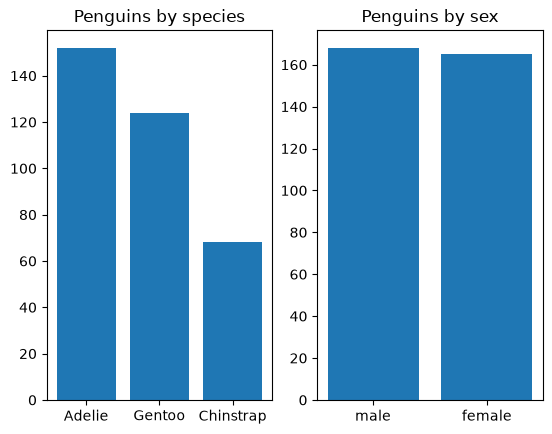

In [47]:
fig, axes = plt.subplots(nrows=1, ncols=2)

species_counts = penguins["species"].value_counts()
axes[0].bar(species_counts.index, species_counts.values)
axes[0].set_title("Penguins by species")

sex_counts = penguins["sex"].value_counts()
axes[1].bar(sex_counts.index, sex_counts.values)
axes[1].set_title("Penguins by sex")

plt.show()

**Question**: Copy paste the above figure, modifying them to display the same plots in two rows and one column.

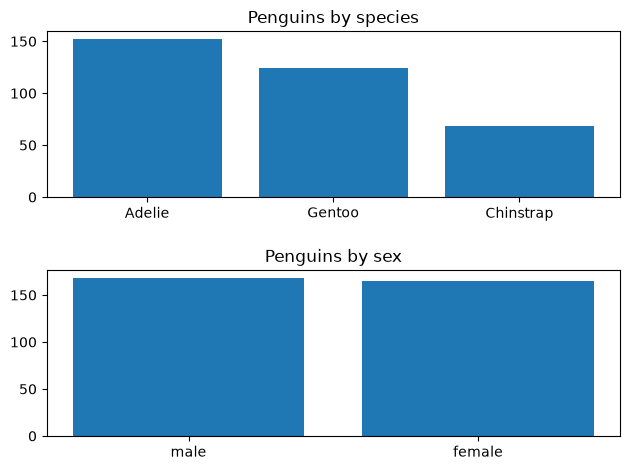

In [48]:
fig, axes = plt.subplots(nrows=2, ncols=1)

species_counts = penguins["species"].value_counts()
axes[0].bar(species_counts.index, species_counts.values)
axes[0].set_title("Penguins by species")

sex_counts = penguins["sex"].value_counts()
axes[1].bar(sex_counts.index, sex_counts.values)
axes[1].set_title("Penguins by sex")

fig.tight_layout(w_pad=2, h_pad=2)

plt.show()

## IV. Understand the Figure and Axes

The next example gives the objects descriptive names. The names could be `fig` and `ax`; longer names are used here to emphasize what each variable stores.

`figsize=(width, height)` controls the overall size in inches. You do not need to memorize particular dimensions—choose enough room for the labels and marks to remain readable.

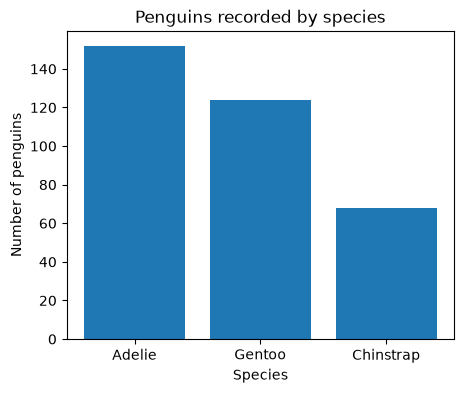

In [49]:
penguin_figure, species_axes = plt.subplots(figsize=(5, 4))

species_axes.bar(species_counts.index, species_counts.values)
species_axes.set_title("Penguins recorded by species")
species_axes.set_xlabel("Species")
species_axes.set_ylabel("Number of penguins")

plt.show()

The Axes methods follow a useful pattern:

- `ax.bar()` adds the principal marks.
- `ax.set_title()` gives the graph a purpose.
- `ax.set_xlabel()` and `ax.set_ylabel()` explain the scales.

The ticks are the positions and labels along an axis. Matplotlib chooses them automatically in many cases, but you can revise them when they are crowded or unclear.

**Question 5:** For the plot above, identify the Figure, the Axes, the marks, the x-axis categories, and the quantity encoded by bar height.

**Answer:** The figsize is 5 by 4 inches.The X axes is `Species` and Y axes is `Number of penguins`.





## V. Build a categorical frequency chart

A bar chart is appropriate when the x-axis represents distinct categories. First prepare a small count table; then give its category labels and counts to `ax.bar()`.

Use `.value_counts()` with `sort=False` when you want the original category order rather than ordering by frequency. Use `.sort_values()` when a deliberate order would make comparison easier.

**Question 6:** Create a frequency table for `island`, order it from the largest count to the smallest, and build a direct Matplotlib bar chart. Add a descriptive title and axis labels.

Your code should create both `fig` and `ax`.

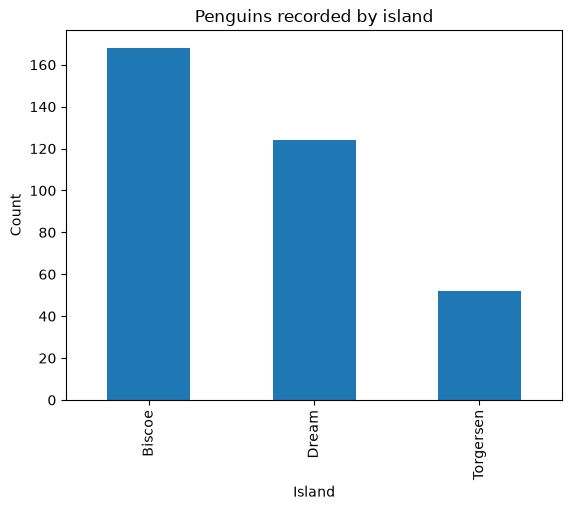

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

In [50]:
# Create island_counts, then make the plot.

island_counts = penguins["island"].value_counts()
island_counts.plot.bar(
    title="Penguins recorded by island", 
    xlabel="Island", 
    ylabel="Count"
)
plt.show()
island_counts

**Question 7:** Revise the chart so the bars appear in alphabetical island order. Does the new order make the comparison easier or harder? Defend your answer briefly.

**Answer:** It didn't matter as they are already in alphabetical order





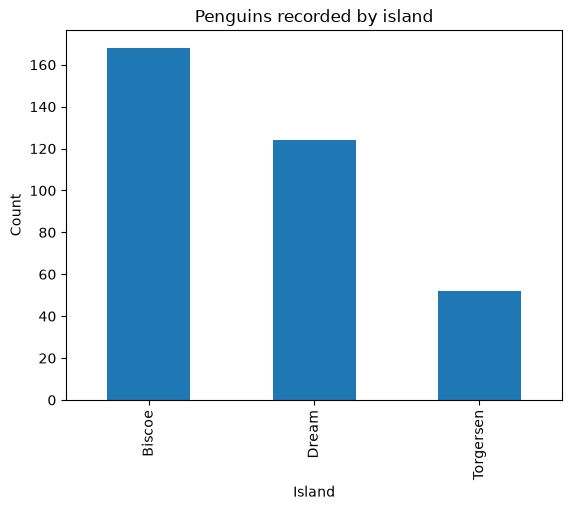

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

In [51]:
# Create the revised frequency table and plot.

island_counts = penguins["island"].value_counts()
island_counts.plot.bar(
    title="Penguins recorded by island", 
    xlabel="Island", 
    ylabel="Count"
)
plt.show()
island_counts

## VI. Visualize a quantitative distribution

A histogram shows the distribution of a quantitative variable. Unlike a bar chart, its x-axis is a number line. Matplotlib divides the number line into intervals called **bins**, then counts how many observations fall within each interval.

Missing values cannot be placed on a number line. `.dropna()` removes missing values from the selected Series before plotting.

In [52]:
body_mass = penguins["body_mass_g"]
body_mass

0      3750.0
1      3800.0
2      3250.0
3         NaN
4      3450.0
        ...  
339    4000.0
340    3400.0
341    3775.0
342    4100.0
343    3775.0
Name: body_mass_g, Length: 344, dtype: float64

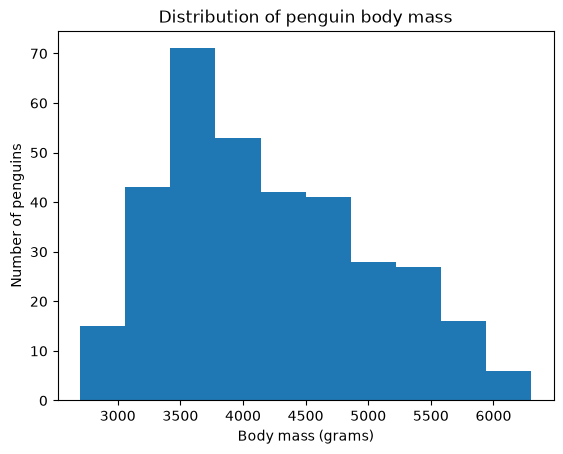

In [53]:
body_mass = penguins["body_mass_g"].dropna()

fig, ax = plt.subplots()
ax.hist(body_mass)
ax.set_title("Distribution of penguin body mass")
ax.set_xlabel("Body mass (grams)")
ax.set_ylabel("Number of penguins")
plt.show()

**Question 8:** What does one histogram bar represent? Why would a bar chart of every distinct `body_mass_g` value be less useful for this question?

**Answer:** The histogram easily demonstrate the distribution of penguin body mass as its a float. Bar chart wouldn't be as useful as we wouldn't be able to do the comparision directly





### Examine the role of bins

The `bins` argument controls how many intervals Matplotlib uses. Too few bins may hide structure; too many can make random variation look important. There is no universally correct number. Compare reasonable choices and select one that communicates the broad pattern without excessive noise.

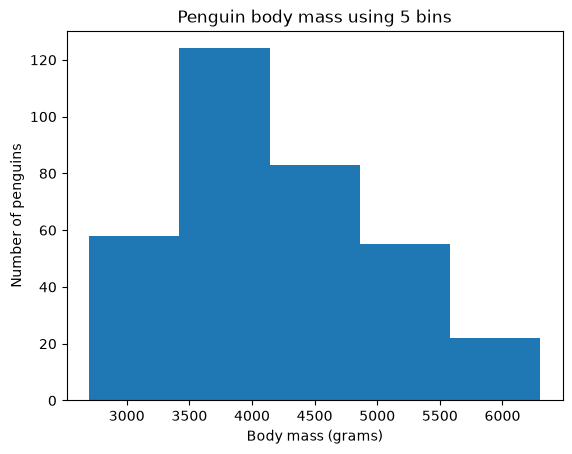

In [54]:
fig, ax = plt.subplots()
ax.hist(body_mass, bins=5)
ax.set_title("Penguin body mass using 5 bins")
ax.set_xlabel("Body mass (grams)")
ax.set_ylabel("Number of penguins")
plt.show()

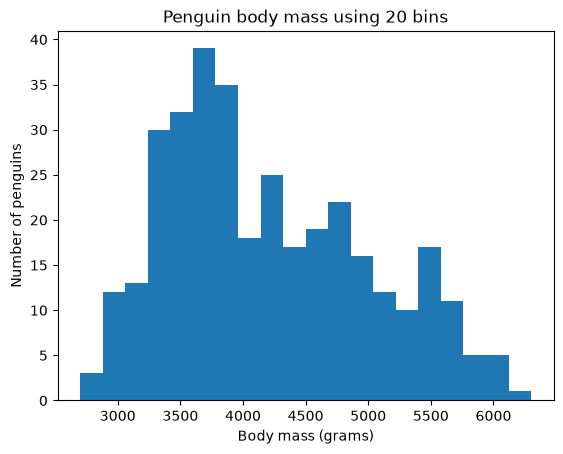

In [55]:
fig, ax = plt.subplots()
ax.hist(body_mass, bins=20)
ax.set_title("Penguin body mass using 20 bins")
ax.set_xlabel("Body mass (grams)")
ax.set_ylabel("Number of penguins")
plt.show()

**Question 9:** Compare the 5-bin and 20-bin versions. Identify one feature that becomes more visible and one feature that becomes less stable or harder to interpret as the number of bins increases.

**Answer:** Body mass intervals are more visible in 5-bin compared to 20-bin. 





**Question 10:** Create a histogram of `flipper_length_mm`. Try at least two reasonable bin counts, then keep the version you believe communicates the distribution most clearly. Add a title and axis labels, and explain your bin choice.

**Answer:**





In [56]:
flipper_length_mm = penguins["flipper_length_mm"].dropna()

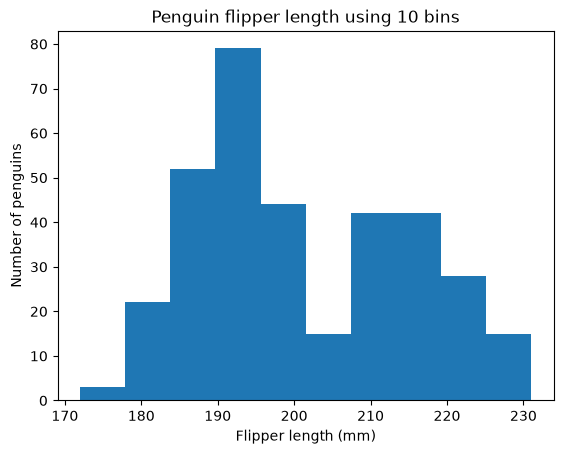

In [57]:
# Try one bin choice.
fig, ax = plt.subplots()
ax.hist(flipper_length_mm, bins=10)
ax.set_title("Penguin flipper length using 10 bins")
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Number of penguins")
plt.show()

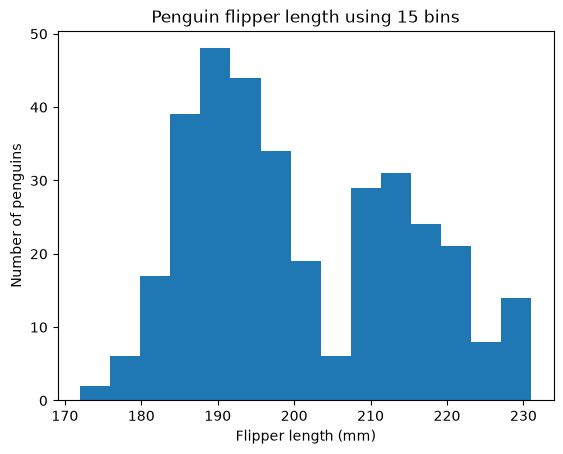

In [58]:
# Try another bin choice, then keep or revise the clearer version.
fig, ax = plt.subplots()
ax.hist(flipper_length_mm, bins=15)
ax.set_title("Penguin flipper length using 15 bins")
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Number of penguins")
plt.show()

<br><br><br>

### Check your work

A complete histogram should use a quantitative Series with missing values removed, pass that Series to `ax.hist()`, and label what the horizontal and vertical scales mean. One possible structure is shown below. Your selected bin count and wording may differ.

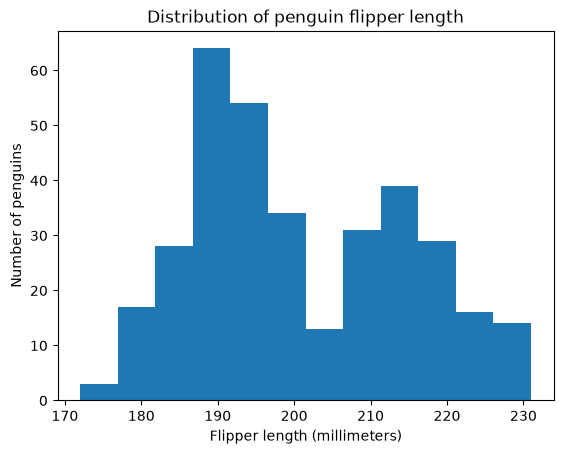

In [59]:
flipper_length = penguins["flipper_length_mm"].dropna()

fig, ax = plt.subplots()
ax.hist(flipper_length, bins=12)
ax.set_title("Distribution of penguin flipper length")
ax.set_xlabel("Flipper length (millimeters)")
ax.set_ylabel("Number of penguins")
plt.show()

## VII. Make a chart readable without overdecorating it

Good default formatting is restrained. Prioritize a meaningful title, explicit units, readable tick labels, and sufficient contrast. Color can support readability, but it should not distract from the data.

The optional `color` argument controls the fill and `edgecolor` outlines the bars. These are useful options, not the main idea of the graph.

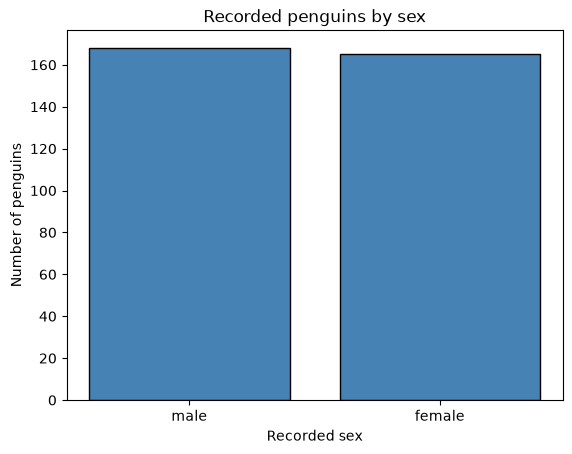

In [60]:
sex_counts = penguins["sex"].value_counts()

fig, ax = plt.subplots()
ax.bar(
    sex_counts.index,
    sex_counts.values,
    color="steelblue",
    edgecolor="black",
)
ax.set_title("Recorded penguins by sex")
ax.set_xlabel("Recorded sex")
ax.set_ylabel("Number of penguins")
plt.show()

If category labels are long, `ax.tick_params(axis="x", labelrotation=...)` can rotate them. Use rotation only when it improves readability.

**Question 11:** Create a bar chart of penguin counts by `year`. Use a restrained color, label both axes, and write a title that tells the reader exactly what is counted. Explain why a bar chart is reasonable even though years are stored as numbers.

**Answer:** Bar chart shows clear comparision of the the penguins count each year.





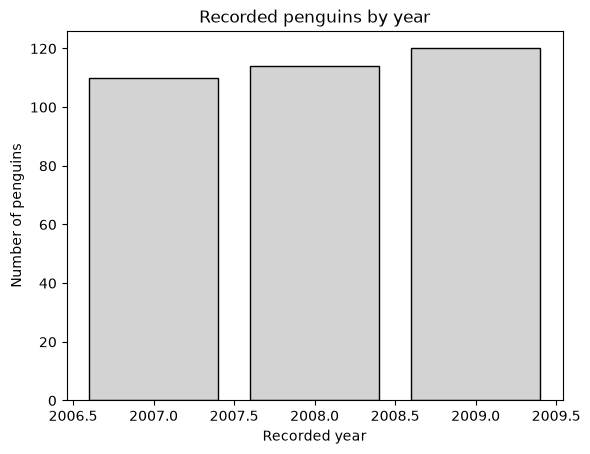

In [61]:
# Prepare the counts and create the chart.

year_counts = penguins["year"].value_counts()

fig, ax = plt.subplots()
ax.bar(
    year_counts.index,
    year_counts.values,
    color="lightgray",
    edgecolor="black",
)
ax.set_title("Recorded penguins by year")
ax.set_xlabel("Recorded year")
ax.set_ylabel("Number of penguins")
plt.show()

## VIII. Save a completed Figure

Call `fig.savefig()` after constructing the chart and before or after `plt.show()`. The filename extension chooses the image format.

- `dpi=150` provides a useful resolution for a submitted PNG.
- `bbox_inches="tight"` reduces unnecessary outer whitespace.

The method belongs to the Figure because the entire canvas is being saved.

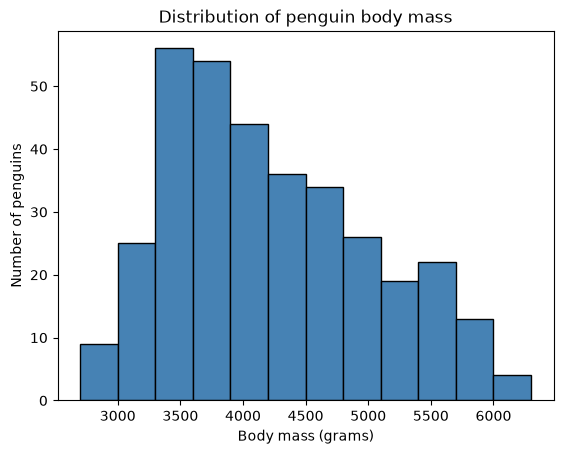

In [62]:
fig, ax = plt.subplots()
ax.hist(body_mass, bins=12, color="steelblue", edgecolor="black")
ax.set_title("Distribution of penguin body mass")
ax.set_xlabel("Body mass (grams)")
ax.set_ylabel("Number of penguins")

fig.savefig(
    "penguin_body_mass_histogram.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [63]:
Path("penguin_body_mass_histogram.png").exists()

True

**Question 12:** Locate `penguin_body_mass_histogram.png` in the VS Code Explorer and open it. Are the title, labels, and complete plotting area visible? Describe one check you made before accepting the export.

**Answer:** Yes the complete plotting area is visible and I try zooming in and out to make sure it wasn't pixelated





## IX. Diagnose and revise a weak graph

The following code runs, but the resulting chart communicates poorly. A graph can be technically valid and still be difficult or misleading to read.

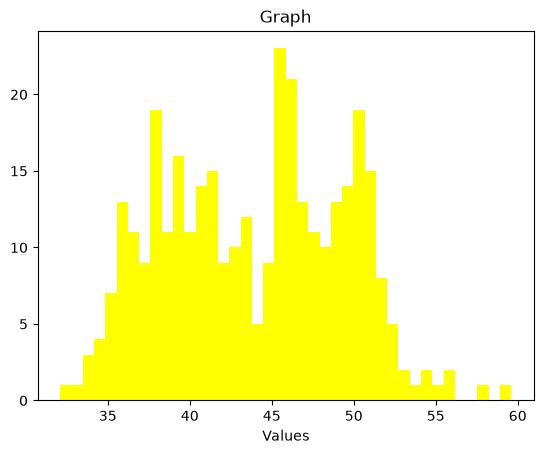

In [64]:
fig, ax = plt.subplots()
ax.hist(penguins["bill_length_mm"].dropna(), bins=40, color="yellow")
ax.set_title("Graph")
ax.set_xlabel("Values")
plt.show()

**Question 13:** Identify at least three weaknesses in the graph. Then revise it using a more informative title and labels, a reasonable bin count, and restrained styling. Briefly explain how your revision helps the reader.

**Answer:** 1- Bars colour too brights. 2- Bin number too high. 3- yaxes is not labeled





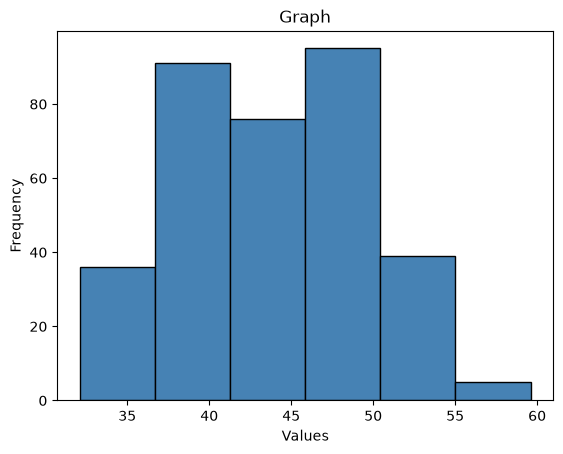

In [65]:
# Create the revised graph.
fig, ax = plt.subplots()
ax.hist(penguins["bill_length_mm"].dropna(), bins=6, color="steelblue", edgecolor="black")
ax.set_title("Graph")
ax.set_xlabel("Values")
ax.set_ylabel("Frequency")
plt.show()

**Question 14:** Choose the better display for each question—a bar chart or a histogram—and justify each choice in one sentence.

A. How many recorded penguins came from each island?  
B. How are recorded bill depths distributed?  
C. How many recorded penguins belong to each species?

**Answer:** A. Bar chart as we dealing with categories. B. Histogram as we dealing with float. C. Bar chart as we dealing with categories again.





## X. Density plot demonstration

A density display is another way to show the shape of a quantitative distribution. Matplotlib can make a **density-normalized histogram** by setting `density=True` in `ax.hist()`. The bars then show density instead of counts.

This example uses only Matplotlib's plotting methods and the `body_mass` Series prepared earlier. It is for recognition only; you are not expected to reproduce it in Lab 4. We will introduce smooth density curves later when comparing groups with Seaborn.

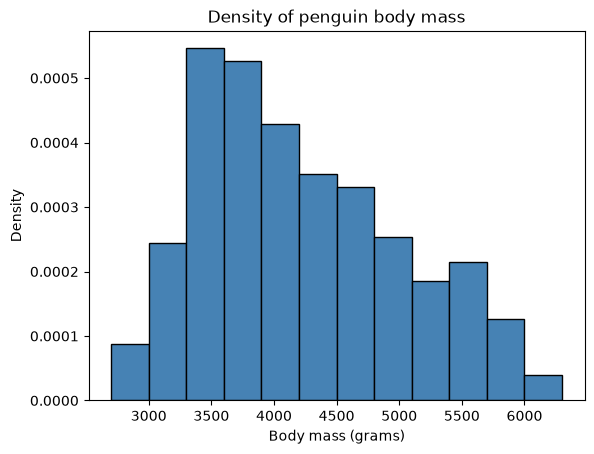

In [66]:
fig, ax = plt.subplots()
histogram_result = ax.hist(
    body_mass,
    bins=12,
    density=True,
    color="steelblue",
    edgecolor="black",
)
ax.set_title("Density of penguin body mass")
ax.set_xlabel("Body mass (grams)")
ax.set_ylabel("Density")
plt.show()

A density-normalized histogram is not a count graph, and its vertical axis is not the number of penguins. The total area of all the bars equals 1. Compare this display with the earlier count histogram: the bins show the same observations, but the vertical scale has changed.

In addition to drawing the histogram, `ax.hist()` returns three useful results. The assignment `density_values, bin_edges, patches = ax.hist(...)` stores each result in a separate variable:

- `density_values` contains the height of each bar. Because this histogram uses `density=True`, these heights are densities rather than counts.
- `bin_edges` contains the boundaries of the bins. There is one more boundary than there are bars because each bar has a left and right edge.
- `patches` contains the Matplotlib rectangle objects drawn for the bars. These objects can be used for later formatting, although we will not modify them here.

Subtracting neighboring values in `bin_edges` gives each bar's width. For every bar, area is density times width. The following calculation adds those areas.

In [67]:
density_values = histogram_result[0]
bin_edges      = histogram_result[1]

bin_widths = bin_edges[1:] - bin_edges[:-1]
bar_areas = density_values * bin_widths
total_area = bar_areas.sum()
total_area

np.float64(0.9999999999999999)

## XI. Independent investigation

**Question 15:** Pose and investigate one defensible univariate question using `penguins.csv`. Your work must:

- State a question about **quantitative variable**.
- Choose a bar chart or histogram that matches the variable and question.
- Prepare the needed Series or frequency table, including an appropriate missing-value decision.
- Use `fig, ax = plt.subplots()` and a direct Matplotlib plotting method.
- Include a descriptive title and labeled axes with units when relevant.
- Use a deliberate category order or histogram bin count.
- Explain what one plotted mark represents.
- Describe the main pattern without claiming that this sample represents all penguins.
- Save the final figure exactly as `Lab4_Independent_Plot.png`.

Do not reproduce a graph already completed earlier in this notebook.

**Question and interpretation:** How is body mass distributed among the penguins in the dataset?





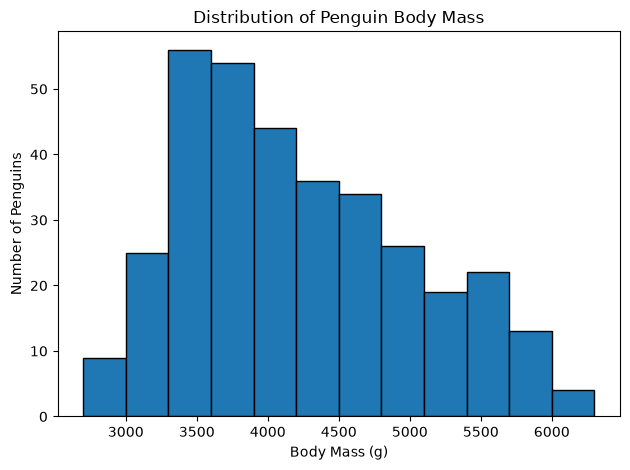

In [68]:
# Prepare the data, construct the final chart, and save the Figure.
# Your final code must create Lab4_Independent_Plot.png.

# Select body mass and remove missing values
body_mass = penguins["body_mass_g"].dropna()

# Create a histogram
fig, ax = plt.subplots()

ax.hist(body_mass, bins=12, edgecolor="black")

ax.set_title("Distribution of Penguin Body Mass")
ax.set_xlabel("Body Mass (g)")
ax.set_ylabel("Number of Penguins")

plt.tight_layout()

# Save the figure
fig.savefig("Lab4_Independent_Plot.png")

plt.show()

In [69]:
Path("Lab4_Independent_Plot.png").exists()

True

## XII. Submission check

Before submitting:

- Add your name and date at the top of the notebook.
- Restart the kernel and run all cells from top to bottom.
- Confirm that every numbered question has a response.
- Inspect every chart for readable titles, labels, ticks, and marks.
- Confirm that the final file check for `Lab4_Independent_Plot.png` returns `True`.
- Export the completed notebook to HTML and open the HTML to inspect it.
- Submit both the completed HTML export and `Lab4_Independent_Plot.png`.

Do not submit `penguin_body_mass_histogram.png`; it is only the guided save-file example.